In [ ]:
# WEEK 2: EXPLORATORY DATA ANALYSIS AND VISUALIZATION

# Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the publicly available Titanic dataset
df = sns.load_dataset("titanic")

# Display basic information
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five records
display(df.head())

Dataset loaded successfully!
Number of rows: 891
Number of columns: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
# STEP 2: INITIAL DATA EXPLORATION

# Display dataset structure
print("DATASET INFORMATION")
df.info()

# Check column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Calculate missing-value percentages
print("\nMISSING VALUE PERCENTAGES")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

# Check duplicate records
print("\nDUPLICATE RECORDS")
print("Number of duplicate rows:", df.duplicated().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

COLUMN NAMES
['survived', 'pclass', 'sex', 'age', 'sibsp',

In [ ]:
# STEP 3: STATISTICAL ANALYSIS

# 1. Numerical summary statistics
print("NUMERICAL SUMMARY STATISTICS")

display(df.describe().T.round(2))

# 2. Categorical summary statistics
print("\nCATEGORICAL SUMMARY STATISTICS")

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

display(df[categorical_columns].describe().T)

# 3. Passenger survival counts
print("\nSURVIVAL COUNTS")

print(df["survived"].value_counts().rename({
    0: "Did not survive",
    1: "Survived"
}))

# 4. Overall survival percentage
print("\nOVERALL SURVIVAL RATE")

survival_rate = df["survived"].mean() * 100

print(f"Survival rate: {survival_rate:.2f}%")
print(f"Non-survival rate: {100 - survival_rate:.2f}%")

NUMERICAL SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
sibsp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33



CATEGORICAL SUMMARY STATISTICS


,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
adult_male,891,2,True,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549
alone,891,2,True,537



SURVIVAL COUNTS
survived
Did not survive    549
Survived           342
Name: count, dtype: int64

OVERALL SURVIVAL RATE
Survival rate: 38.38%
Non-survival rate: 61.62%


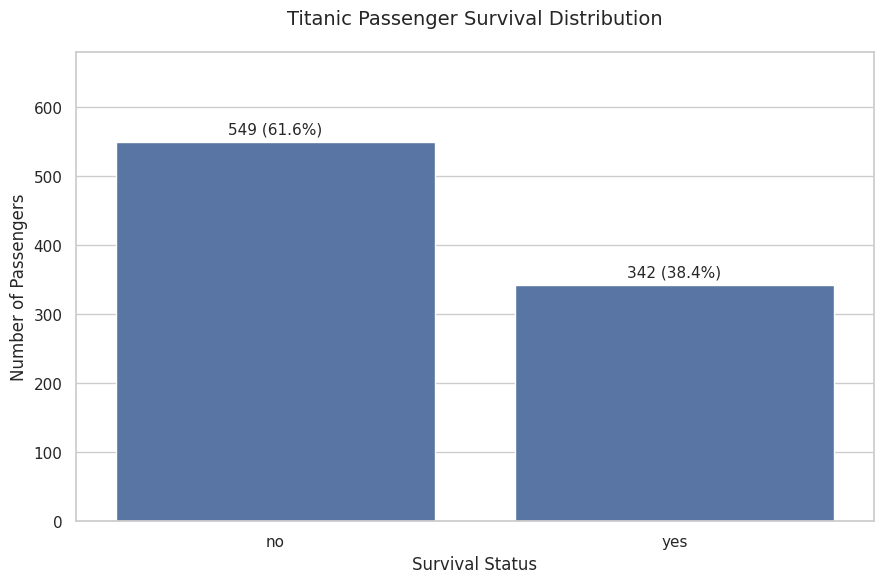

In [ ]:
# Improved Titanic Passenger Survival Distribution

plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=df,
    x="alive",
    order=["no", "yes"]
)

plt.title("Titanic Passenger Survival Distribution", fontsize=14, pad=20)
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")

# Add extra space above the bars
ax.set_ylim(0, 680)

# Annotate each bar with count and percentage
for patch in ax.patches:
    count = int(patch.get_height())
    percentage = (count / len(df)) * 100

    ax.annotate(
        f"{count} ({percentage:.1f}%)",
        (patch.get_x() + patch.get_width() / 2, count + 8),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()

In [ ]:
# STEP 5: SURVIVAL ANALYSIS BY PASSENGER CLASS

# Calculate passenger counts and survival rates
class_summary = (
    df.groupby("class", observed=False)["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename columns
class_summary.columns = [
    "Passenger Class",
    "Total Passengers",
    "Survivors",
    "Survival Rate"
]

# Convert survival rate into a percentage
class_summary["Survival Rate (%)"] = (
    class_summary["Survival Rate"] * 100
).round(2)

# Display results
print("SURVIVAL ANALYSIS BY PASSENGER CLASS")
display(class_summary)

SURVIVAL ANALYSIS BY PASSENGER CLASS


,Passenger Class,Total Passengers,Survivors,Survival Rate,Survival Rate (%)
0,First,216,136,0.629630,62.96
1,Second,184,87,0.472826,47.28
2,Third,491,119,0.242363,24.24


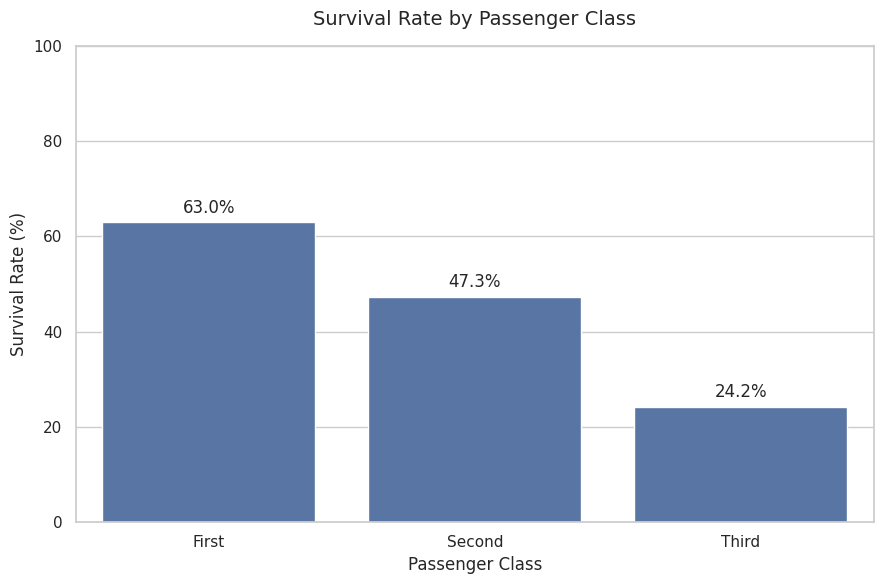

In [ ]:
# STEP 6: VISUALIZE SURVIVAL RATE BY PASSENGER CLASS

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=class_summary,
    x="Passenger Class",
    y="Survival Rate (%)"
)

plt.title(
    "Survival Rate by Passenger Class",
    fontsize=14,
    pad=15
)

plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

# Display percentages above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

In [ ]:
# STEP 7: SURVIVAL ANALYSIS BY GENDER

gender_summary = (
    df.groupby("sex")["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

gender_summary.columns = [
    "Gender",
    "Total Passengers",
    "Survivors",
    "Survival Rate"
]

gender_summary["Survival Rate (%)"] = (
    gender_summary["Survival Rate"] * 100
).round(2)

print("SURVIVAL ANALYSIS BY GENDER")
display(gender_summary)

SURVIVAL ANALYSIS BY GENDER


,Gender,Total Passengers,Survivors,Survival Rate,Survival Rate (%)
0,female,314,233,0.742038,74.20
1,male,577,109,0.188908,18.89


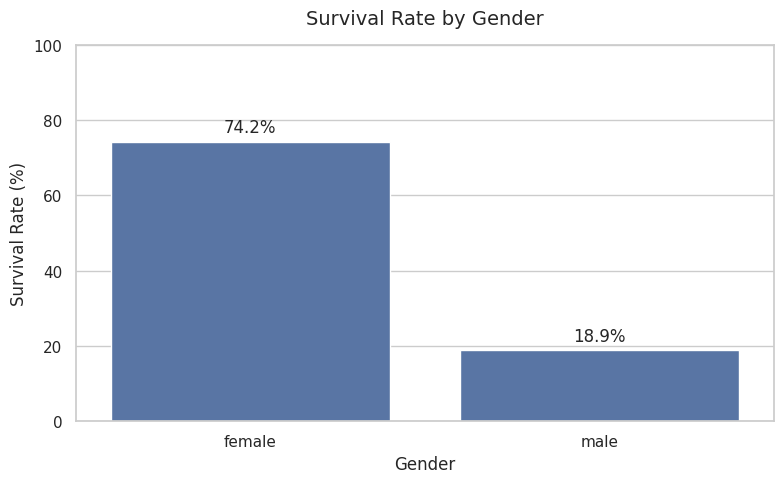

In [ ]:
# STEP 7A: VISUALIZE SURVIVAL RATE BY GENDER

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=gender_summary,
    x="Gender",
    y="Survival Rate (%)"
)

plt.title("Survival Rate by Gender", fontsize=14, pad=15)
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

In [ ]:
# STEP 8: SURVIVAL ANALYSIS BY GENDER AND PASSENGER CLASS

# Group passengers by class and gender
gender_class_summary = (
    df.groupby(["class", "sex"], observed=True)["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename columns
gender_class_summary.columns = [
    "Passenger Class",
    "Gender",
    "Total Passengers",
    "Survivors",
    "Survival Rate"
]

# Convert survival rate into a percentage
gender_class_summary["Survival Rate (%)"] = (
    gender_class_summary["Survival Rate"] * 100
).round(2)

print("SURVIVAL RATE BY GENDER AND PASSENGER CLASS")
display(gender_class_summary)

SURVIVAL RATE BY GENDER AND PASSENGER CLASS


,Passenger Class,Gender,Total Passengers,Survivors,Survival Rate,Survival Rate (%)
0,First,female,94,91,0.968085,96.81
1,First,male,122,45,0.368852,36.89
2,Second,female,76,70,0.921053,92.11
3,Second,male,108,17,0.157407,15.74
4,Third,female,144,72,0.500000,50.00
5,Third,male,347,47,0.135447,13.54


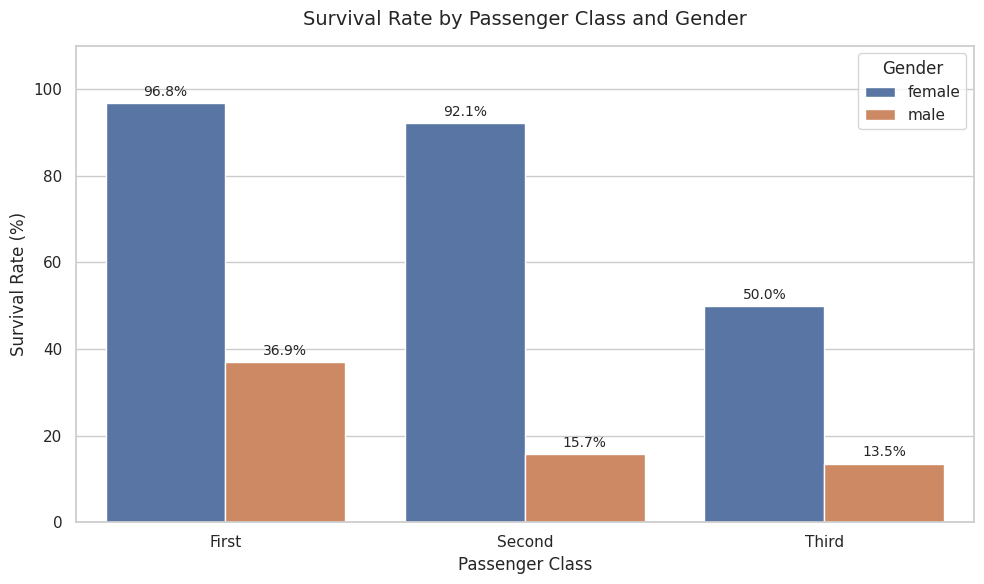

In [ ]:
# STEP 8A: VISUALIZE SURVIVAL BY GENDER AND PASSENGER CLASS

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=gender_class_summary,
    x="Passenger Class",
    y="Survival Rate (%)",
    hue="Gender",
    order=["First", "Second", "Third"],
    hue_order=["female", "male"]
)

plt.title(
    "Survival Rate by Passenger Class and Gender",
    fontsize=14,
    pad=15
)

plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 110)
plt.legend(title="Gender")

# Display percentages above the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [ ]:
# STEP 9: AGE ANALYSIS BY SURVIVAL STATUS

# Keep only records with an observed age for this analysis
age_data = df.dropna(subset=["age"]).copy()

# Calculate age statistics for each survival group
age_summary = (
    age_data.groupby("alive", observed=True)["age"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .reset_index()
)

print("AGE STATISTICS BY SURVIVAL STATUS")
display(age_summary)

print("\nRecords included in age analysis:", len(age_data))
print("Records excluded because age was missing:", df["age"].isnull().sum())

AGE STATISTICS BY SURVIVAL STATUS


,alive,count,mean,median,std,min,max
0,no,424,30.63,28.0,14.17,1.00,74.0
1,yes,290,28.34,28.0,14.95,0.42,80.0



Records included in age analysis: 714
Records excluded because age was missing: 177


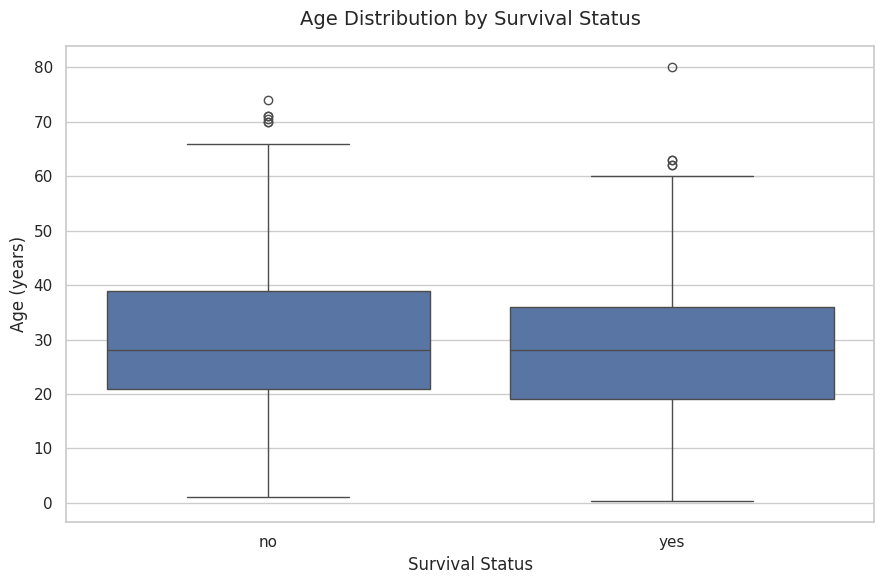

In [ ]:
# STEP 9A: AGE DISTRIBUTION BY SURVIVAL STATUS

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=age_data,
    x="alive",
    y="age",
    order=["no", "yes"]
)

plt.title("Age Distribution by Survival Status", fontsize=14, pad=15)
plt.xlabel("Survival Status")
plt.ylabel("Age (years)")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 10: NUMERICAL AGE COMPARISON

age_summary = (
    age_data.groupby("alive", observed=True)["age"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .reset_index()
)

print("Age statistics by survival status:")
display(age_summary)

print("\nMissing age records excluded from this analysis:",
      df["age"].isnull().sum())

print("Records included:", len(age_data))

Age statistics by survival status:


,alive,count,mean,median,std,min,max
0,no,424,30.63,28.0,14.17,1.00,74.0
1,yes,290,28.34,28.0,14.95,0.42,80.0



Missing age records excluded from this analysis: 177
Records included: 714


In [ ]:
# STEP 11: FARE ANALYSIS BY SURVIVAL STATUS

fare_summary = (
    df.groupby("alive", observed=True)["fare"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .reset_index()
)

print("FARE STATISTICS BY SURVIVAL STATUS")
display(fare_summary)

FARE STATISTICS BY SURVIVAL STATUS


,alive,count,mean,median,std,min,max
0,no,549,22.12,10.5,31.39,0.0,263.00
1,yes,342,48.40,26.0,66.60,0.0,512.33


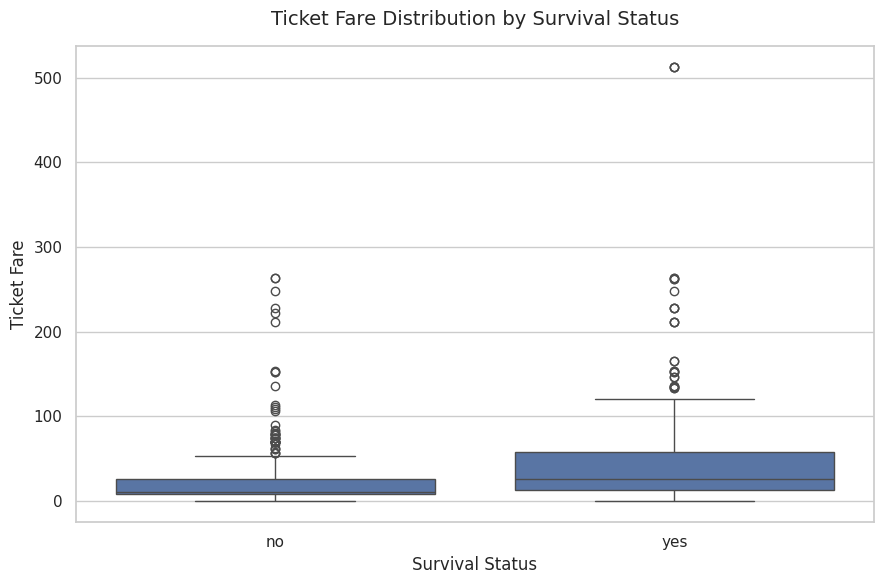

In [ ]:
# STEP 11A: TICKET FARE DISTRIBUTION BY SURVIVAL STATUS

plt.figure(figsize=(9, 6))

ax = sns.boxplot(
    data=df,
    x="alive",
    y="fare",
    order=["no", "yes"]
)

plt.title("Ticket Fare Distribution by Survival Status", fontsize=14, pad=15)
plt.xlabel("Survival Status")
plt.ylabel("Ticket Fare")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 12: FARE STATISTICS BY SURVIVAL STATUS

fare_summary = (
    df.groupby("alive", observed=True)["fare"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .reset_index()
)

print("FARE STATISTICS BY SURVIVAL STATUS")
display(fare_summary)

FARE STATISTICS BY SURVIVAL STATUS


,alive,count,mean,median,std,min,max
0,no,549,22.12,10.5,31.39,0.0,263.00
1,yes,342,48.40,26.0,66.60,0.0,512.33


CORRELATION MATRIX


,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.34,-0.08,-0.04,0.08,0.26
pclass,-0.34,1.00,-0.37,0.08,0.02,-0.55
age,-0.08,-0.37,1.00,-0.31,-0.19,0.10
sibsp,-0.04,0.08,-0.31,1.00,0.41,0.16
parch,0.08,0.02,-0.19,0.41,1.00,0.22
fare,0.26,-0.55,0.10,0.16,0.22,1.00


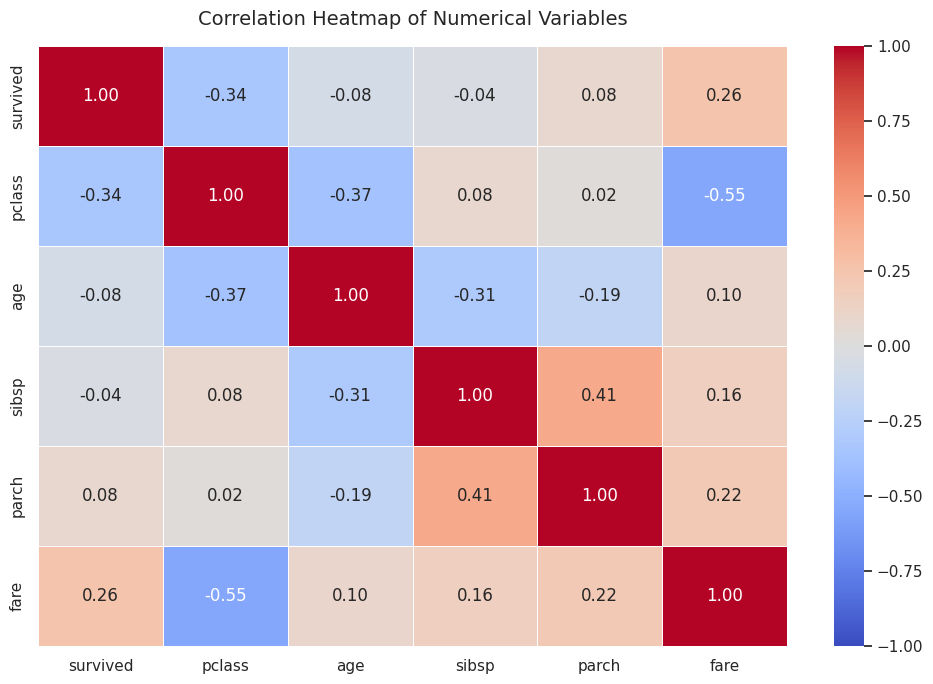

In [ ]:
# STEP 13: CORRELATION ANALYSIS

# Select important numerical variables
correlation_columns = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

correlation_data = df[correlation_columns]

# Calculate Pearson correlation coefficients
correlation_matrix = correlation_data.corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(2))

# Visualize correlations using a heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 14: FAMILY SIZE ANALYSIS

# Create a new variable for family size
family_df = df.copy()

family_df["family_size"] = (
    family_df["sibsp"] +
    family_df["parch"] +
    1
)

print("First five family-size records:")
display(
    family_df[["sibsp", "parch", "family_size", "survived"]].head()
)

# Calculate survival statistics by family size
family_summary = (
    family_df.groupby("family_size")["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

family_summary.columns = [
    "Family Size",
    "Passenger Count",
    "Survivors",
    "Survival Rate"
]

family_summary["Survival Rate (%)"] = (
    family_summary["Survival Rate"] * 100
).round(2)

print("\nSURVIVAL STATISTICS BY FAMILY SIZE")
display(family_summary)

First five family-size records:


,sibsp,parch,family_size,survived
0,1,0,2,0
1,1,0,2,1
2,0,0,1,1
3,1,0,2,1
4,0,0,1,0



SURVIVAL STATISTICS BY FAMILY SIZE


,Family Size,Passenger Count,Survivors,Survival Rate,Survival Rate (%)
0,1,537,163,0.303538,30.35
1,2,161,89,0.552795,55.28
2,3,102,59,0.578431,57.84
3,4,29,21,0.724138,72.41
4,5,15,3,0.200000,20.00
5,6,22,3,0.136364,13.64
6,7,12,4,0.333333,33.33
7,8,6,0,0.000000,0.00
8,11,7,0,0.000000,0.00


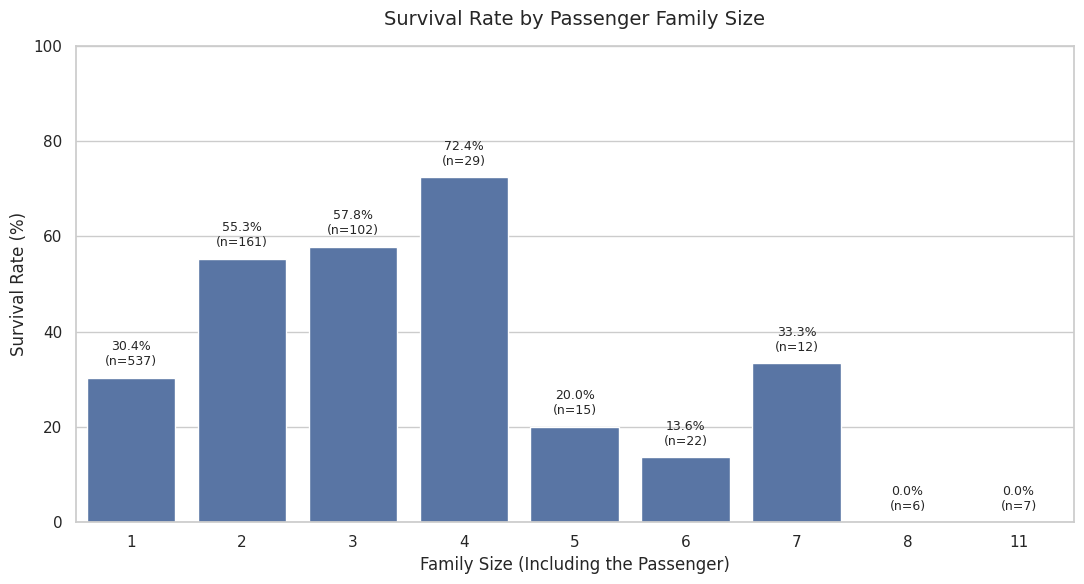

In [ ]:
# STEP 15: SURVIVAL RATE BY FAMILY SIZE

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=family_summary,
    x="Family Size",
    y="Survival Rate (%)"
)

plt.title("Survival Rate by Passenger Family Size", fontsize=14, pad=15)
plt.xlabel("Family Size (Including the Passenger)")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

# Annotate each bar with the survival rate and sample size
for patch, (_, row) in zip(ax.patches, family_summary.iterrows()):
    height = patch.get_height()

    ax.annotate(
        f"{row['Survival Rate (%)']:.1f}%\n(n={int(row['Passenger Count'])})",
        (
            patch.get_x() + patch.get_width() / 2,
            height + 2
        ),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
# STEP 16: TICKET FARE ANALYSIS BY PASSENGER CLASS

fare_class_summary = (
    df.groupby("class", observed=True)["fare"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .reset_index()
)

print("TICKET FARE STATISTICS BY PASSENGER CLASS")
display(fare_class_summary)

TICKET FARE STATISTICS BY PASSENGER CLASS


,class,count,mean,median,std,min,max
0,First,216,84.15,60.29,78.38,0.0,512.33
1,Second,184,20.66,14.25,13.42,0.0,73.50
2,Third,491,13.68,8.05,11.78,0.0,69.55


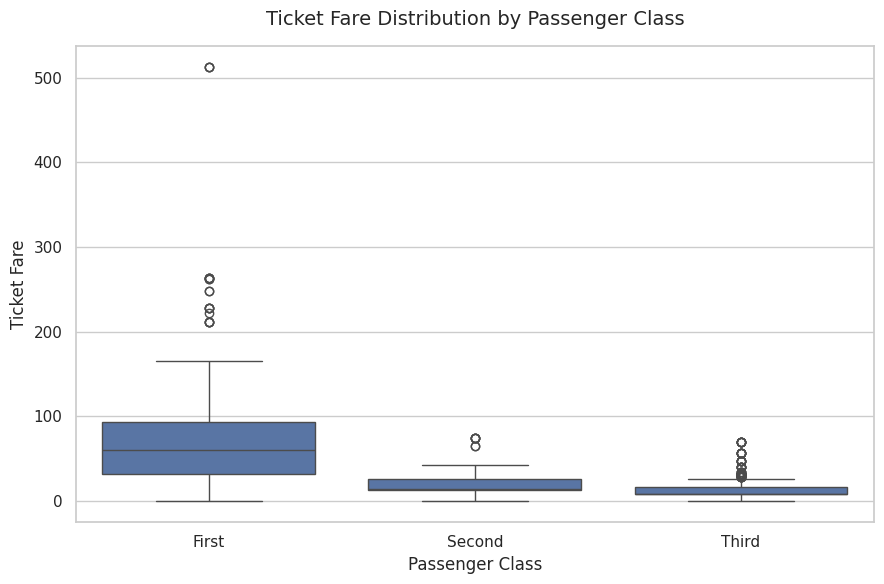

In [ ]:
# STEP 16A: FARE DISTRIBUTION BY PASSENGER CLASS

plt.figure(figsize=(9, 6))

ax = sns.boxplot(
    data=df,
    x="class",
    y="fare",
    order=["First", "Second", "Third"]
)

plt.title("Ticket Fare Distribution by Passenger Class", fontsize=14, pad=15)
plt.xlabel("Passenger Class")
plt.ylabel("Ticket Fare")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 17: NUMERICAL FARE COMPARISON BY PASSENGER CLASS

fare_class_summary = (
    df.groupby("class", observed=True)["fare"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .reset_index()
)

fare_class_summary.columns = [
    "Passenger Class",
    "Passenger Count",
    "Mean Fare",
    "Median Fare",
    "Standard Deviation",
    "Minimum Fare",
    "Maximum Fare"
]

print("FARE STATISTICS BY PASSENGER CLASS")
display(fare_class_summary)

FARE STATISTICS BY PASSENGER CLASS


,Passenger Class,Passenger Count,Mean Fare,Median Fare,Standard Deviation,Minimum Fare,Maximum Fare
0,First,216,84.15,60.29,78.38,0.0,512.33
1,Second,184,20.66,14.25,13.42,0.0,73.50
2,Third,491,13.68,8.05,11.78,0.0,69.55


In [ ]:
# STEP 18: INVESTIGATE ZERO-FARE RECORDS

# Count passengers with zero fare
zero_fare_count = (df["fare"] == 0).sum()

print("Total passengers:", len(df))
print("Passengers with zero fare:", zero_fare_count)

print(
    "Percentage with zero fare:",
    round(zero_fare_count / len(df) * 100, 2),
    "%"
)

# Summarize zero-fare records by passenger class
zero_fare_summary = (
    df.assign(zero_fare=df["fare"] == 0)
    .groupby("class", observed=True)
    .agg(
        Total_Passengers=("fare", "size"),
        Zero_Fare_Passengers=("zero_fare", "sum")
    )
    .reset_index()
)

zero_fare_summary["Zero Fare Percentage (%)"] = (
    zero_fare_summary["Zero_Fare_Passengers"]
    / zero_fare_summary["Total_Passengers"]
    * 100
).round(2)

print("\nZero-fare records by passenger class:")
display(zero_fare_summary)

Total passengers: 891
Passengers with zero fare: 15
Percentage with zero fare: 1.68 %

Zero-fare records by passenger class:


,class,Total_Passengers,Zero_Fare_Passengers,Zero Fare Percentage (%)
0,First,216,5,2.31
1,Second,184,6,3.26
2,Third,491,4,0.81


In [ ]:
# STEP 19: INSPECT ZERO-FARE PASSENGER RECORDS

zero_fare_records = df.loc[
    df["fare"] == 0,
    [
        "survived",
        "pclass",
        "sex",
        "age",
        "sibsp",
        "parch",
        "fare",
        "embarked"
    ]
]

print("Number of zero-fare records:", len(zero_fare_records))

print("\nZero-fare records:")
display(zero_fare_records)

Number of zero-fare records: 15

Zero-fare records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked
179,0,3,male,36.0,0,0,0.0,S
263,0,1,male,40.0,0,0,0.0,S
271,1,3,male,25.0,0,0,0.0,S
277,0,2,male,NaN,0,0,0.0,S
302,0,3,male,19.0,0,0,0.0,S
413,0,2,male,NaN,0,0,0.0,S
466,0,2,male,NaN,0,0,0.0,S
481,0,2,male,NaN,0,0,0.0,S
597,0,3,male,49.0,0,0,0.0,S
633,0,1,male,NaN,0,0,0.0,S


In [ ]:
# STEP 20: SURVIVAL ANALYSIS BY AGE GROUP

# Use only passengers with recorded ages
age_group_df = df.dropna(subset=["age"]).copy()

# Create age groups
age_group_df["age_group"] = pd.cut(
    age_group_df["age"],
    bins=[-np.inf, 18, 36, 60, np.inf],
    labels=["Under 18", "18–35", "36–59", "60+"],
    right=False
)

# Calculate passenger counts and survival rates
age_group_summary = (
    age_group_df.groupby("age_group", observed=True)["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

age_group_summary.columns = [
    "Age Group",
    "Passenger Count",
    "Survivors",
    "Survival Rate"
]

age_group_summary["Survival Rate (%)"] = (
    age_group_summary["Survival Rate"] * 100
).round(2)

print("SURVIVAL STATISTICS BY AGE GROUP")
display(age_group_summary)

print("\nPassengers included:", len(age_group_df))
print("Passengers excluded because age was missing:", df["age"].isnull().sum())

SURVIVAL STATISTICS BY AGE GROUP


,Age Group,Passenger Count,Survivors,Survival Rate,Survival Rate (%)
0,Under 18,113,61,0.539823,53.98
1,18–35,384,146,0.380208,38.02
2,36–59,191,76,0.397906,39.79
3,60+,26,7,0.269231,26.92



Passengers included: 714
Passengers excluded because age was missing: 177


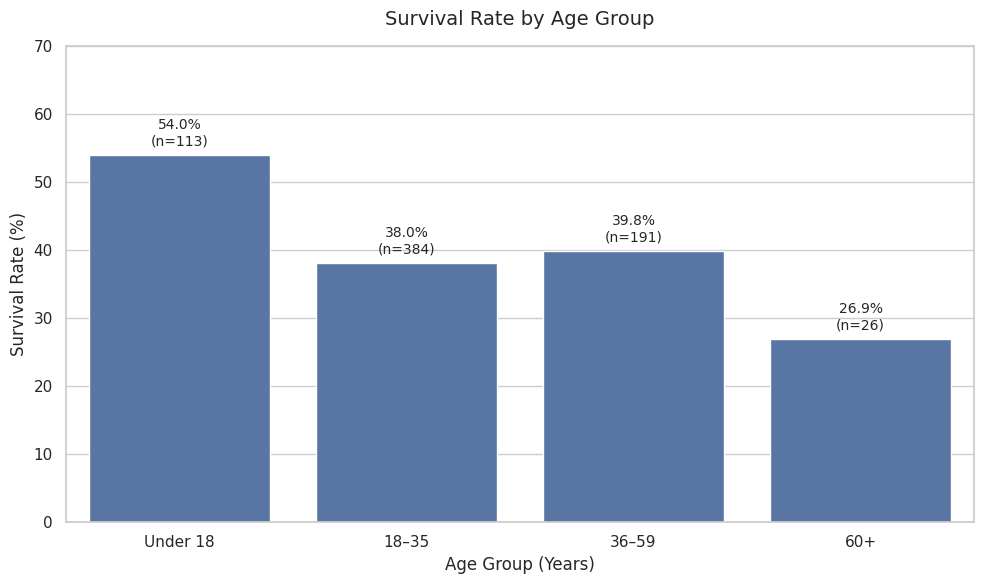

In [ ]:
# STEP 20A: VISUALIZE SURVIVAL RATE BY AGE GROUP

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=age_group_summary,
    x="Age Group",
    y="Survival Rate (%)",
    order=["Under 18", "18–35", "36–59", "60+"]
)

plt.title("Survival Rate by Age Group", fontsize=14, pad=15)
plt.xlabel("Age Group (Years)")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 70)

# Display the survival percentage and group size above each bar
for patch, (_, row) in zip(ax.patches, age_group_summary.iterrows()):
    height = patch.get_height()

    ax.annotate(
        f"{row['Survival Rate (%)']:.1f}%\n(n={int(row['Passenger Count'])})",
        (patch.get_x() + patch.get_width() / 2, height + 1),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

CORRELATION MATRIX


,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.34,-0.08,-0.04,0.08,0.26
pclass,-0.34,1.00,-0.37,0.08,0.02,-0.55
age,-0.08,-0.37,1.00,-0.31,-0.19,0.10
sibsp,-0.04,0.08,-0.31,1.00,0.41,0.16
parch,0.08,0.02,-0.19,0.41,1.00,0.22
fare,0.26,-0.55,0.10,0.16,0.22,1.00


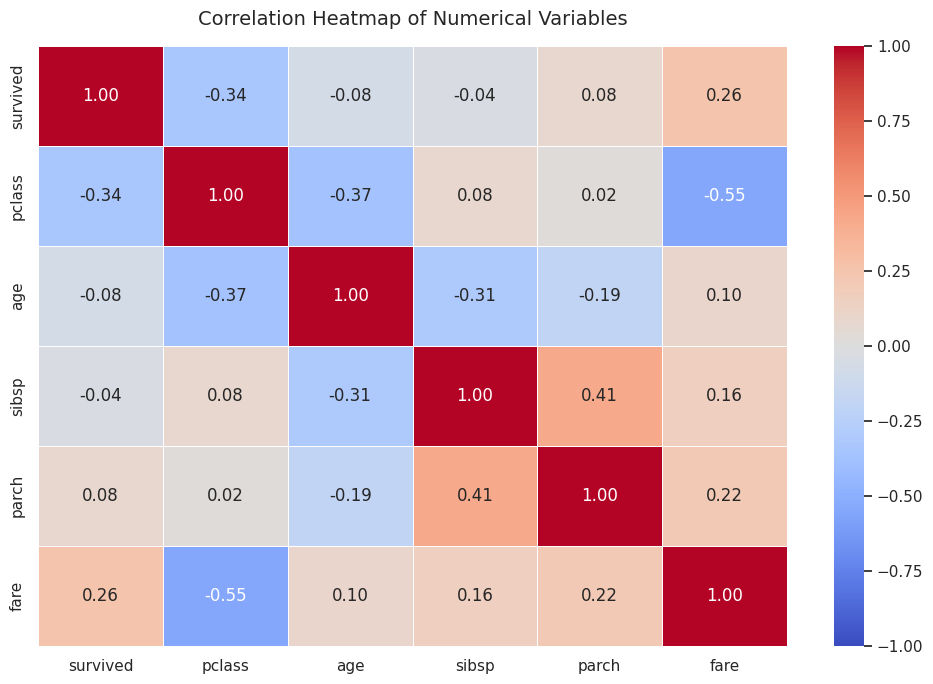

In [ ]:
# STEP 21: CORRELATION ANALYSIS

# Select numerical variables for analysis
correlation_columns = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

correlation_data = df[correlation_columns]

# Calculate Pearson correlation coefficients
correlation_matrix = correlation_data.corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(2))

# Create the heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 22: SURVIVAL ANALYSIS BY EMBARKATION TOWN

# Exclude the two records where embarkation town is missing
embark_data = df.dropna(subset=["embark_town"]).copy()

# Calculate passenger counts and survival rates
embark_summary = (
    embark_data.groupby("embark_town", observed=True)["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

embark_summary.columns = [
    "Embarkation Town",
    "Passenger Count",
    "Survivors",
    "Survival Rate"
]

embark_summary["Survival Rate (%)"] = (
    embark_summary["Survival Rate"] * 100
).round(2)

print("SURVIVAL STATISTICS BY EMBARKATION TOWN")
display(embark_summary)

print("\nRecords included:", len(embark_data))
print("Records excluded because embarkation town was missing:",
      df["embark_town"].isnull().sum())

SURVIVAL STATISTICS BY EMBARKATION TOWN


,Embarkation Town,Passenger Count,Survivors,Survival Rate,Survival Rate (%)
0,Cherbourg,168,93,0.553571,55.36
1,Queenstown,77,30,0.389610,38.96
2,Southampton,644,217,0.336957,33.70



Records included: 889
Records excluded because embarkation town was missing: 2


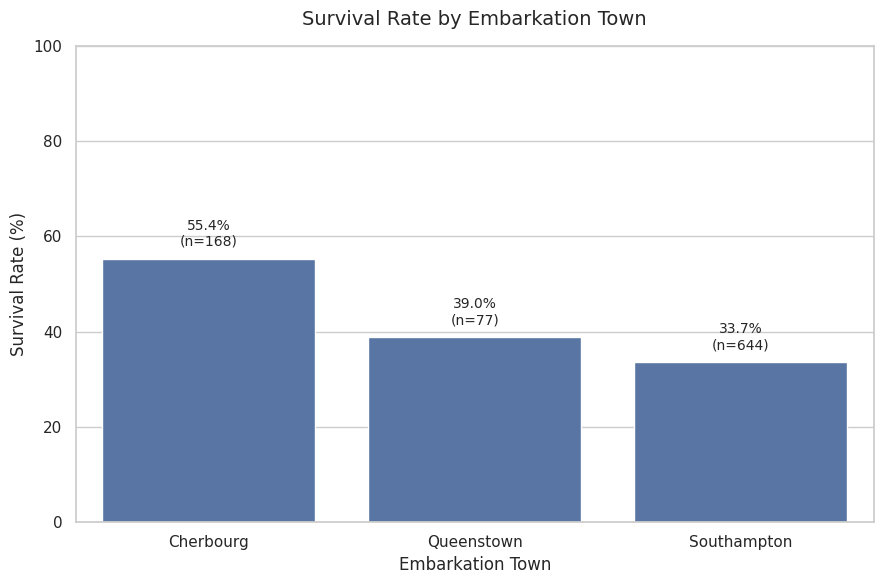

In [ ]:
# STEP 22A: VISUALIZE SURVIVAL RATE BY EMBARKATION TOWN

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=embark_summary,
    x="Embarkation Town",
    y="Survival Rate (%)"
)

plt.title("Survival Rate by Embarkation Town", fontsize=14, pad=15)
plt.xlabel("Embarkation Town")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

# Display survival rates and sample sizes
for patch, (_, row) in zip(ax.patches, embark_summary.iterrows()):
    ax.annotate(
        f"{row['Survival Rate (%)']:.1f}%\n(n={int(row['Passenger Count'])})",
        (
            patch.get_x() + patch.get_width() / 2,
            patch.get_height() + 2
        ),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [ ]:
# STEP 23: PASSENGER CLASS DISTRIBUTION BY EMBARKATION TOWN

# Count passengers in each class for each embarkation town
class_counts_by_town = pd.crosstab(
    df["embark_town"],
    df["class"]
)

print("PASSENGER COUNTS BY EMBARKATION TOWN")
display(class_counts_by_town)

# Calculate the percentage distribution within each town
class_percent_by_town = pd.crosstab(
    df["embark_town"],
    df["class"],
    normalize="index"
) * 100

print("\nPASSENGER CLASS DISTRIBUTION WITHIN EACH TOWN (%)")
display(class_percent_by_town.round(2))

PASSENGER COUNTS BY EMBARKATION TOWN


class,First,Second,Third
embark_town,,,
Cherbourg,85,17,66
Queenstown,2,3,72
Southampton,127,164,353



PASSENGER CLASS DISTRIBUTION WITHIN EACH TOWN (%)


class,First,Second,Third
embark_town,,,
Cherbourg,50.60,10.12,39.29
Queenstown,2.60,3.90,93.51
Southampton,19.72,25.47,54.81


In [ ]:
# STEP 24: SURVIVAL RATE BY EMBARKATION TOWN AND PASSENGER CLASS

# Exclude records with missing embarkation town
town_class_df = df.dropna(subset=["embark_town"]).copy()

# Calculate survival statistics for each town-class combination
town_class_summary = (
    town_class_df.groupby(
        ["embark_town", "class"],
        observed=True
    )["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename the columns
town_class_summary.columns = [
    "Embarkation Town",
    "Passenger Class",
    "Passenger Count",
    "Survivors",
    "Survival Rate"
]

# Convert rates to percentages
town_class_summary["Survival Rate (%)"] = (
    town_class_summary["Survival Rate"] * 100
).round(2)

print("SURVIVAL RATE BY EMBARKATION TOWN AND CLASS")
display(town_class_summary)

SURVIVAL RATE BY EMBARKATION TOWN AND CLASS


,Embarkation Town,Passenger Class,Passenger Count,Survivors,Survival Rate,Survival Rate (%)
0,Cherbourg,First,85,59,0.694118,69.41
1,Cherbourg,Second,17,9,0.529412,52.94
2,Cherbourg,Third,66,25,0.378788,37.88
3,Queenstown,First,2,1,0.500000,50.00
4,Queenstown,Second,3,2,0.666667,66.67
5,Queenstown,Third,72,27,0.375000,37.50
6,Southampton,First,127,74,0.582677,58.27
7,Southampton,Second,164,76,0.463415,46.34
8,Southampton,Third,353,67,0.189802,18.98


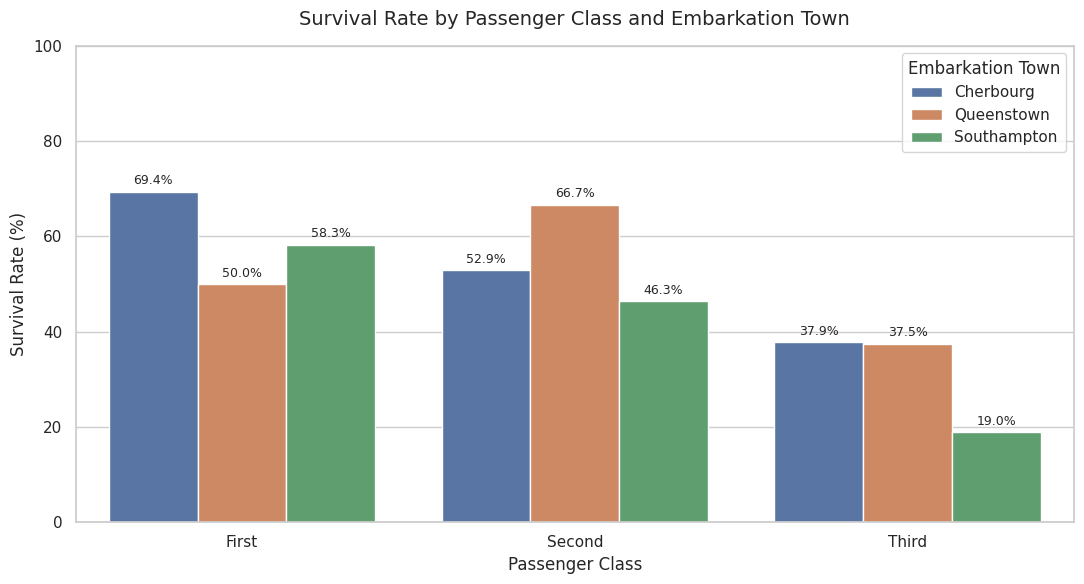

In [ ]:
# STEP 25: SURVIVAL RATE BY PASSENGER CLASS AND EMBARKATION TOWN

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=town_class_summary,
    x="Passenger Class",
    y="Survival Rate (%)",
    hue="Embarkation Town",
    order=["First", "Second", "Third"],
    hue_order=["Cherbourg", "Queenstown", "Southampton"]
)

plt.title(
    "Survival Rate by Passenger Class and Embarkation Town",
    fontsize=14,
    pad=15
)

plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Embarkation Town")

# Add survival-rate labels above the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

OVERALL AGE SUMMARY
Passengers with recorded age: 714
Missing age records: 177
Mean age: 29.70 years
Median age: 28.00 years
Minimum age: 0.42 years
Maximum age: 80.00 years


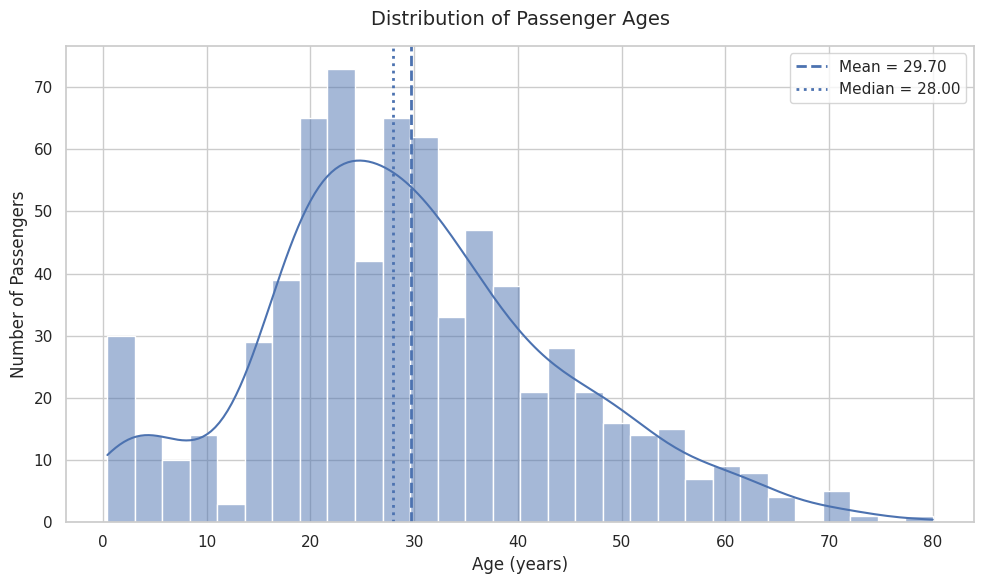

In [ ]:
# STEP 26: OVERALL AGE DISTRIBUTION

# Use only passengers with recorded ages
age_data = df.dropna(subset=["age"]).copy()

# Calculate summary statistics
mean_age = age_data["age"].mean()
median_age = age_data["age"].median()

print("OVERALL AGE SUMMARY")
print("Passengers with recorded age:", len(age_data))
print("Missing age records:", df["age"].isnull().sum())
print(f"Mean age: {mean_age:.2f} years")
print(f"Median age: {median_age:.2f} years")
print(f"Minimum age: {age_data['age'].min():.2f} years")
print(f"Maximum age: {age_data['age'].max():.2f} years")

# Create age distribution histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    data=age_data,
    x="age",
    bins=30,
    kde=True
)

plt.axvline(
    mean_age,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_age:.2f}"
)

plt.axvline(
    median_age,
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_age:.2f}"
)

plt.title("Distribution of Passenger Ages", fontsize=14, pad=15)
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.legend()

plt.tight_layout()
plt.show()

TICKET-FARE SUMMARY
Number of passengers: 891
Mean fare: 32.20
Median fare: 14.45
Minimum fare: 0.00
Maximum fare: 512.33


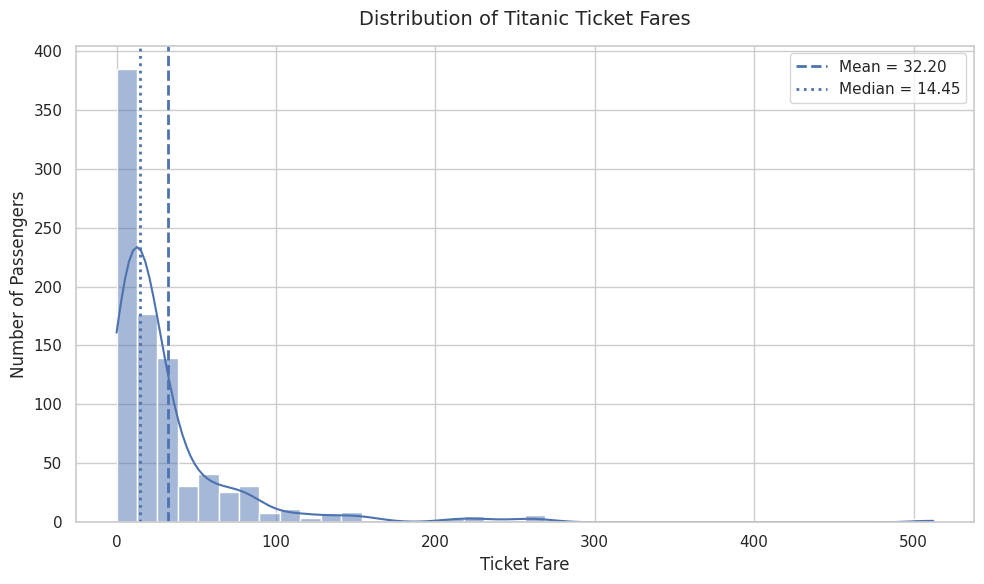

In [ ]:
# STEP 27: TICKET-FARE DISTRIBUTION

# Calculate fare statistics
fare_mean = df["fare"].mean()
fare_median = df["fare"].median()

print("TICKET-FARE SUMMARY")
print("Number of passengers:", df["fare"].count())
print(f"Mean fare: {fare_mean:.2f}")
print(f"Median fare: {fare_median:.2f}")
print(f"Minimum fare: {df['fare'].min():.2f}")
print(f"Maximum fare: {df['fare'].max():.2f}")

# Plot the fare distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="fare",
    bins=40,
    kde=True
)

plt.axvline(
    fare_mean,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {fare_mean:.2f}"
)

plt.axvline(
    fare_median,
    linestyle=":",
    linewidth=2,
    label=f"Median = {fare_median:.2f}"
)

plt.title("Distribution of Titanic Ticket Fares", fontsize=14, pad=15)
plt.xlabel("Ticket Fare")
plt.ylabel("Number of Passengers")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# STEP 28: INVESTIGATE THE HIGHEST TICKET FARES

# Select relevant columns for investigation
fare_investigation = df[
    ["survived", "pclass", "class", "sex", "age", "fare"]
].copy()

# Sort passengers by fare, from highest to lowest
highest_fares = fare_investigation.nlargest(10, "fare")

print("TOP 10 HIGHEST TICKET FARES")
display(highest_fares)

# Compare the highest fares with the overall fare distribution
print("\nOVERALL FARE STATISTICS")
print(f"Mean fare: {df['fare'].mean():.2f}")
print(f"Median fare: {df['fare'].median():.2f}")
print(f"Maximum fare: {df['fare'].max():.2f}")

print("\nFare skewness:", round(df["fare"].skew(), 2))

TOP 10 HIGHEST TICKET FARES


,survived,pclass,class,sex,age,fare
258,1,1,First,female,35.0,512.3292
679,1,1,First,male,36.0,512.3292
737,1,1,First,male,35.0,512.3292
27,0,1,First,male,19.0,263.0000
88,1,1,First,female,23.0,263.0000
341,1,1,First,female,24.0,263.0000
438,0,1,First,male,64.0,263.0000
311,1,1,First,female,18.0,262.3750
742,1,1,First,female,21.0,262.3750
118,0,1,First,male,24.0,247.5208



OVERALL FARE STATISTICS
Mean fare: 32.20
Median fare: 14.45
Maximum fare: 512.33

Fare skewness: 4.79


In [ ]:
# STEP 29: QUANTIFY TICKET-FARE OUTLIERS

# Calculate quartiles and interquartile range
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)
IQR = Q3 - Q1

# Calculate the outlier thresholds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify observations outside the IQR bounds
fare_outliers = df[
    (df["fare"] < lower_bound) |
    (df["fare"] > upper_bound)
].copy()

print("FARE OUTLIER ANALYSIS")
print(f"First quartile (Q1): {Q1:.2f}")
print(f"Third quartile (Q3): {Q3:.2f}")
print(f"Interquartile range (IQR): {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"Number of flagged outliers: {len(fare_outliers)}")
print(
    f"Percentage flagged: "
    f"{len(fare_outliers) / len(df) * 100:.2f}%"
)

print("\nFlagged observations by passenger class:")
display(
    fare_outliers.groupby("class", observed=True)
    .agg(
        Outlier_Count=("fare", "size"),
        Mean_Fare=("fare", "mean"),
        Maximum_Fare=("fare", "max")
    )
    .round(2)
)

FARE OUTLIER ANALYSIS
First quartile (Q1): 7.91
Third quartile (Q3): 31.00
Interquartile range (IQR): 23.09
Lower bound: -26.72
Upper bound: 65.63
Number of flagged outliers: 116
Percentage flagged: 13.02%

Flagged observations by passenger class:


,Outlier_Count,Mean_Fare,Maximum_Fare
class,,,
First,104,134.88,512.33
Second,5,73.50,73.50
Third,7,69.55,69.55


In [ ]:
# STEP 30: FARE OUTLIER PERCENTAGES BY PASSENGER CLASS

# Define the class order
class_order = ["First", "Second", "Third"]

# Count passengers in each class
class_totals = (
    df["class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

# Count IQR-flagged fares in each class
outlier_counts = (
    fare_outliers["class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

# Build a comparison table
class_outlier_summary = pd.DataFrame({
    "Passenger Class": class_order,
    "Total Passengers": class_totals.values,
    "IQR-Flagged Fares": outlier_counts.values
})

class_outlier_summary["Flagged Percentage (%)"] = (
    class_outlier_summary["IQR-Flagged Fares"]
    / class_outlier_summary["Total Passengers"]
    * 100
).round(2)

print("FARE OUTLIER PERCENTAGES BY PASSENGER CLASS")
display(class_outlier_summary)

FARE OUTLIER PERCENTAGES BY PASSENGER CLASS


,Passenger Class,Total Passengers,IQR-Flagged Fares,Flagged Percentage (%)
0,First,216,104,48.15
1,Second,184,5,2.72
2,Third,491,7,1.43


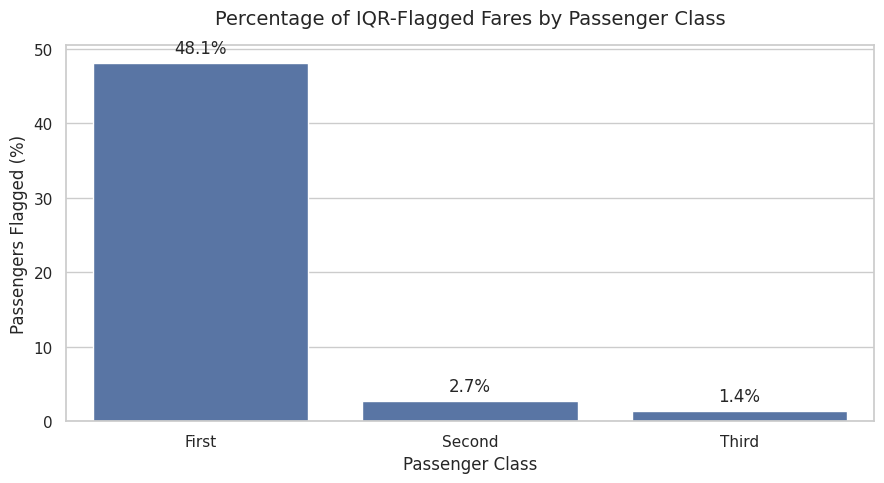

In [ ]:
# STEP 30A: VISUALIZE FARE OUTLIER PERCENTAGES BY CLASS

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=class_outlier_summary,
    x="Passenger Class",
    y="Flagged Percentage (%)",
    order=["First", "Second", "Third"]
)

plt.title(
    "Percentage of IQR-Flagged Fares by Passenger Class",
    fontsize=14,
    pad=15
)

plt.xlabel("Passenger Class")
plt.ylabel("Passengers Flagged (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

SURVIVAL STATISTICS BY TICKET FARE GROUP


,Fare Group,Passenger Count,Survivors,Survival Rate,Survival Rate (%)
0,Q1 - Lowest fares,223,44,0.197309,19.73
1,Q2 - Lower-middle fares,224,68,0.303571,30.36
2,Q3 - Upper-middle fares,222,101,0.454955,45.50
3,Q4 - Highest fares,222,129,0.581081,58.11


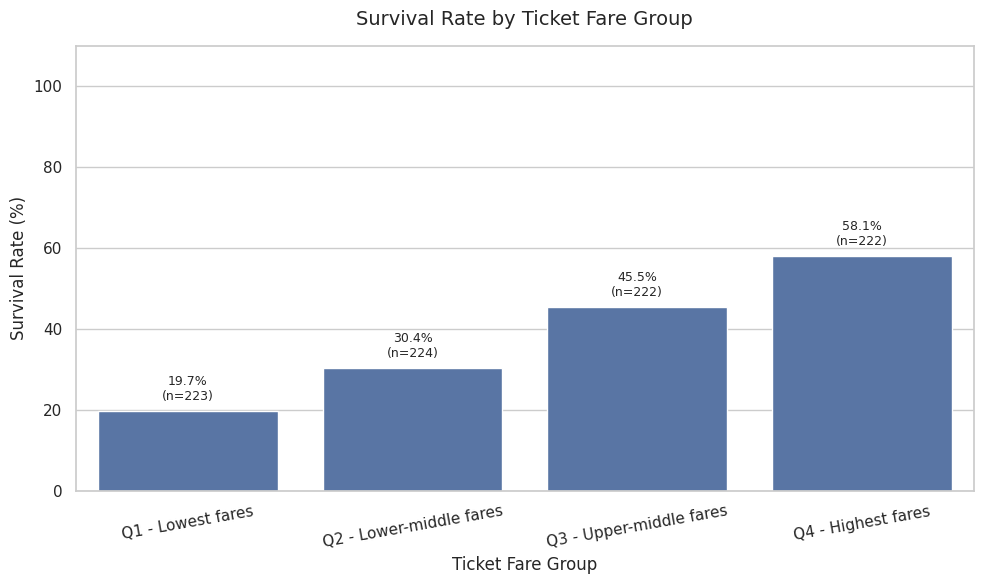

In [ ]:
# STEP 31: SURVIVAL ANALYSIS BY TICKET FARE GROUP

# Create a copy of the original dataset
fare_group_df = df.copy()

# Divide ticket fares into four groups
fare_group_df["fare_group"] = pd.qcut(
    fare_group_df["fare"],
    q=4,
    labels=[
        "Q1 - Lowest fares",
        "Q2 - Lower-middle fares",
        "Q3 - Upper-middle fares",
        "Q4 - Highest fares"
    ]
)

# Calculate passenger counts and survival rates
fare_group_summary = (
    fare_group_df.groupby("fare_group", observed=True)["survived"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename columns
fare_group_summary.columns = [
    "Fare Group",
    "Passenger Count",
    "Survivors",
    "Survival Rate"
]

# Convert survival rate to percentage
fare_group_summary["Survival Rate (%)"] = (
    fare_group_summary["Survival Rate"] * 100
).round(2)

# Display the summary table
print("SURVIVAL STATISTICS BY TICKET FARE GROUP")
display(fare_group_summary)

# Create the chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=fare_group_summary,
    x="Fare Group",
    y="Survival Rate (%)"
)

plt.title("Survival Rate by Ticket Fare Group", fontsize=14, pad=15)
plt.xlabel("Ticket Fare Group")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 110)

# Add percentages and passenger counts
for patch, (_, row) in zip(
    ax.patches,
    fare_group_summary.iterrows()
):
    ax.annotate(
        f"{row['Survival Rate (%)']:.1f}%\n(n={int(row['Passenger Count'])})",
        (
            patch.get_x() + patch.get_width() / 2,
            patch.get_height() + 2
        ),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 32: SUMMARY OF KEY EDA FINDINGS

# Calculate the main survival rates
overall_survival = df["survived"].mean() * 100

class_rates = (
    df.groupby("class", observed=True)["survived"].mean() * 100
)

gender_rates = (
    df.groupby("sex", observed=True)["survived"].mean() * 100
)

town_rates = (
    df.dropna(subset=["embark_town"])
    .groupby("embark_town", observed=True)["survived"]
    .mean() * 100
)

# Calculate the main fare-outlier percentages
fare_q1 = df["fare"].quantile(0.25)
fare_q3 = df["fare"].quantile(0.75)
fare_iqr = fare_q3 - fare_q1
fare_upper_bound = fare_q3 + 1.5 * fare_iqr

fare_outlier_mask = df["fare"] > fare_upper_bound

outlier_class_rates = (
    df.assign(flagged_fare=fare_outlier_mask)
    .groupby("class", observed=True)["flagged_fare"]
    .mean() * 100
)

# Create a summary table
key_findings = pd.DataFrame([
    {
        "Analysis": "Overall survival",
        "Numerical finding": f"{overall_survival:.2f}% survived",
        "Interpretation": "Non-survivors formed the larger outcome group."
    },
    {
        "Analysis": "Passenger class",
        "Numerical finding": (
            f"First: {class_rates['First']:.2f}%; "
            f"Third: {class_rates['Third']:.2f}%"
        ),
        "Interpretation": "Survival rates differed considerably by class."
    },
    {
        "Analysis": "Gender",
        "Numerical finding": (
            f"Female: {gender_rates['female']:.2f}%; "
            f"Male: {gender_rates['male']:.2f}%"
        ),
        "Interpretation": "Female passengers had a higher observed survival rate."
    },
    {
        "Analysis": "Embarkation town",
        "Numerical finding": (
            f"Cherbourg: {town_rates['Cherbourg']:.2f}%; "
            f"Southampton: {town_rates['Southampton']:.2f}%"
        ),
        "Interpretation": "Town-level survival differed; class composition may contribute."
    },
    {
        "Analysis": "Fare distribution",
        "Numerical finding": (
            f"Mean: {df['fare'].mean():.2f}; "
            f"Median: {df['fare'].median():.2f}"
        ),
        "Interpretation": "The mean exceeding the median is consistent with right-skew."
    },
    {
        "Analysis": "Fare outliers",
        "Numerical finding": (
            f"{int(fare_outlier_mask.sum())} records flagged "
            f"({fare_outlier_mask.mean() * 100:.2f}%)"
        ),
        "Interpretation": "IQR flags indicate unusual values, not confirmed errors."
    }
])

print("KEY FINDINGS FROM EXPLORATORY DATA ANALYSIS")
display(key_findings)

KEY FINDINGS FROM EXPLORATORY DATA ANALYSIS


,Analysis,Numerical finding,Interpretation
0,Overall survival,38.38% survived,Non-survivors formed the larger outcome group.
1,Passenger class,First: 62.96%; Third: 24.24%,Survival rates differed considerably by class.
2,Gender,Female: 74.20%; Male: 18.89%,Female passengers had a higher observed surviv...
3,Embarkation town,Cherbourg: 55.36%; Southampton: 33.70%,Town-level survival differed; class compositio...
4,Fare distribution,Mean: 32.20; Median: 14.45,The mean exceeding the median is consistent wi...
5,Fare outliers,116 records flagged (13.02%),"IQR flags indicate unusual values, not confirm..."


In [ ]:
# STEP 33: FINAL DATA VALIDATION FOR THE EDA REPORT

print("=" * 55)
print("FINAL DATA VALIDATION")
print("=" * 55)

# Dataset dimensions
print("\n1. Dataset dimensions")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Missing values
print("\n2. Missing values by column")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_summary[missing_summary["Missing Count"] > 0])

# Duplicate records
print("\n3. Potential duplicate rows")
print("Exact duplicate rows:", df.duplicated().sum())

# Overall survival rate
print("\n4. Overall survival")
print(f"Survival rate: {df['survived'].mean() * 100:.2f}%")
print(f"Non-survival rate: {(1 - df['survived'].mean()) * 100:.2f}%")

# Export important findings
key_findings.to_csv("week2_eda_key_findings.csv", index=False)
class_summary.to_csv("week2_survival_by_class.csv", index=False)
gender_summary.to_csv("week2_survival_by_gender.csv", index=False)
fare_group_summary.to_csv("week2_survival_by_fare_group.csv", index=False)

print("\n5. Summary tables exported successfully.")
print("Files created:")
print("- week2_eda_key_findings.csv")
print("- week2_survival_by_class.csv")
print("- week2_survival_by_gender.csv")
print("- week2_survival_by_fare_group.csv")

FINAL DATA VALIDATION

1. Dataset dimensions
Rows: 891
Columns: 15

2. Missing values by column


,Missing Count,Missing Percentage (%)
age,177,19.87
embarked,2,0.22
deck,688,77.22
embark_town,2,0.22



3. Potential duplicate rows
Exact duplicate rows: 107

4. Overall survival
Survival rate: 38.38%
Non-survival rate: 61.62%

5. Summary tables exported successfully.
Files created:
- week2_eda_key_findings.csv
- week2_survival_by_class.csv
- week2_survival_by_gender.csv
- week2_survival_by_fare_group.csv
